# 06 - Costo de negocio e interpretabilidad

**Objetivo:** pasar de una métrica estadística (AUC-PR) a una decisión de negocio: **¿a partir de qué score conviene generar una alerta?** Después, entender qué variables mueven las predicciones con SHAP.

**Modelo final:** LightGBM sin ajuste de desbalance y con variables crudas (conclusiones de los notebooks 04 y 05).

**Protocolo:**
- El umbral se elige en **validación**.
- El **test se usa por primera vez acá**, una sola vez, para medir el resultado final con el umbral ya fijado.

## Supuestos del modelo de costo
Son supuestos propios, no datos del dataset:
1. Cada transacción con score ≥ umbral genera una **alerta** que se revisa manualmente, con un costo fijo `REVIEW_COST` por revisión.
2. La revisión detecta el fraude sin errores: una alerta sobre un fraude evita la pérdida.
3. Un **fraude no alertado** cuesta el **monto completo** de la transacción.
4. Un no fraude alertado cuesta solo la revisión (no se modela fricción ni pérdida de clientes).

Como el costo de revisión es incierto, se hace un **análisis de sensibilidad** variándolo.

In [28]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
import shap

from src.validation import add_day, temporal_split
from src.evaluate import evaluate, cost_curve, best_threshold, cost_at_threshold

sns.set_theme(style="whitegrid")

## 1. Datos y modelo final

In [29]:
df = add_day(pd.read_parquet("../data/processed/train_merged.parquet"))
for c in df.columns:
    if not pd.api.types.is_numeric_dtype(df[c]):
        df[c] = df[c].astype("category")

train, valid, test = temporal_split(df)

DROP = ["TransactionID", "TransactionDT", "day", "isFraud"]
features = [c for c in df.columns if c not in DROP]

y_train, y_valid, y_test = train["isFraud"], valid["isFraud"], test["isFraud"]
amt_valid, amt_test = valid["TransactionAmt"].values, test["TransactionAmt"].values

In [30]:
params = dict(
    objective="binary", learning_rate=0.05, n_estimators=2000, num_leaves=64,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    random_state=42, n_jobs=-1, verbose=-1,
)
model = lgb.LGBMClassifier(**params)
model.fit(
    train[features], y_train,
    eval_set=[(valid[features], y_valid)], eval_metric="auc",
    callbacks=[lgb.early_stopping(100), lgb.log_evaluation(100)],
)
p_valid = model.predict_proba(valid[features])[:, 1]
p_test = model.predict_proba(test[features])[:, 1]
print("Mejor iteración:", model.best_iteration_)

c:\Users\Carlos\AppData\Local\Programs\Python\Python313\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


Training until validation scores don't improve for 100 rounds
[100]	valid_0's auc: 0.906486	valid_0's binary_logloss: 0.0898731
[200]	valid_0's auc: 0.91775	valid_0's binary_logloss: 0.0856414
[300]	valid_0's auc: 0.920376	valid_0's binary_logloss: 0.0843805
[400]	valid_0's auc: 0.923574	valid_0's binary_logloss: 0.0833867
[500]	valid_0's auc: 0.92428	valid_0's binary_logloss: 0.0831447
[600]	valid_0's auc: 0.925021	valid_0's binary_logloss: 0.0830404
Early stopping, best iteration is:
[559]	valid_0's auc: 0.925052	valid_0's binary_logloss: 0.082948
Mejor iteración: 559


## 2. Curva de costo en validación
Para cada cantidad de alertas se calcula el costo total. El umbral óptimo es el que lo minimiza.

Umbral óptimo: 0.0217  |  alertas: 14.73% de las transacciones  |  costo: $133,162


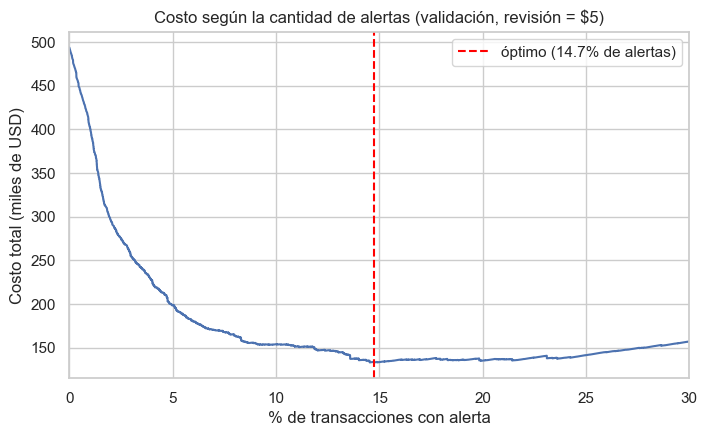

In [31]:
REVIEW_COST = 5.0   # supuesto: costo de revisar una alerta (USD). Se varía en la sección 4.

curve = cost_curve(y_valid, p_valid, amt_valid, REVIEW_COST)
curve["alertas_%"] = 100 * curve["n_flagged"] / len(valid)
best = curve.loc[curve["cost"].idxmin()]
thr = best["threshold"]
print(f"Umbral óptimo: {thr:.4f}  |  alertas: {best['alertas_%']:.2f}% de las transacciones  |  costo: ${best['cost']:,.0f}")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve["alertas_%"], curve["cost"] / 1e3)
ax.axvline(best["alertas_%"], color="red", linestyle="--", label=f"óptimo ({best['alertas_%']:.1f}% de alertas)")
ax.set_xlim(0, 30)
ax.set_xlabel("% de transacciones con alerta"); ax.set_ylabel("Costo total (miles de USD)")
ax.set_title(f"Costo según la cantidad de alertas (validación, revisión = ${REVIEW_COST:.0f})")
plt.savefig("../reports/figures/cost_curve.png", dpi=150, bbox_inches="tight")
ax.legend(); plt.show()

## 3. Evaluación final en test
El umbral elegido en validación se aplica **sin cambios** a test. Se compara contra:
- **Sin modelo:** no se revisa nada, se pierden todos los fraudes.
- **Revisar todo:** se revisa cada transacción.
- **Umbral 0,5:** la regla ingenua.

In [32]:
rows = {
    "validación (umbral óptimo)": cost_at_threshold(y_valid, p_valid, amt_valid, REVIEW_COST, thr),
    "test (umbral de validación)": cost_at_threshold(y_test, p_test, amt_test, REVIEW_COST, thr),
    "test (umbral 0,5)": cost_at_threshold(y_test, p_test, amt_test, REVIEW_COST, 0.5),
}
res = pd.DataFrame(rows).T
res.round(4)

,umbral,alertas_%,precision,recall,costo,costo_sin_modelo,costo_revisar_todo,ahorro_vs_sin_modelo_%
validación (umbral óptimo),0.0217,14.7334,0.1965,0.8336,133161.8549,493820.5910,426515.0,73.0344
test (umbral de validación),0.0217,15.7308,0.1767,0.8013,167984.9766,495244.3967,473180.0,66.0804
"test (umbral 0,5)",0.5000,1.4297,0.8189,0.3376,390276.7297,495244.3967,473180.0,21.1951


In [33]:
# Métricas estadísticas finales en test (primera y única vez)
pd.Series(evaluate(y_test, p_test)).round(4)

auc_pr           0.5441
auc_roc          0.9062
tasa_base        0.0347
recall@prec50    0.5168
recall@prec80    0.3525
dtype: float64

## 4. Sensibilidad al costo de revisión
Para cada costo de revisión se elige el umbral **en validación** y se evalúa en **test**.

In [34]:
rows = []
for rc in [1, 2, 5, 10, 25, 50, 100]:
    t = best_threshold(y_valid, p_valid, amt_valid, rc)
    r = cost_at_threshold(y_test, p_test, amt_test, rc, t)
    rows.append({"costo_revisión": rc, **{k: r[k] for k in ["umbral", "alertas_%", "precision", "recall", "costo", "costo_sin_modelo", "ahorro_vs_sin_modelo_%"]}})
sens = pd.DataFrame(rows).set_index("costo_revisión")
sens.round(3)

,umbral,alertas_%,precision,recall,costo,costo_sin_modelo,ahorro_vs_sin_modelo_%
costo_revisión,,,,,,,
1,0.006,44.254,0.074,0.939,62154.552,495244.397,87.450
2,0.012,25.096,0.121,0.873,102178.218,495244.397,79.368
5,0.022,15.731,0.177,0.801,167984.977,495244.397,66.080
10,0.040,9.431,0.261,0.710,235460.665,495244.397,52.456
25,0.073,5.798,0.368,0.615,338801.935,495244.397,31.589
50,0.158,3.119,0.551,0.496,422576.274,495244.397,14.673
100,0.399,1.660,0.777,0.372,523609.157,495244.397,-5.727


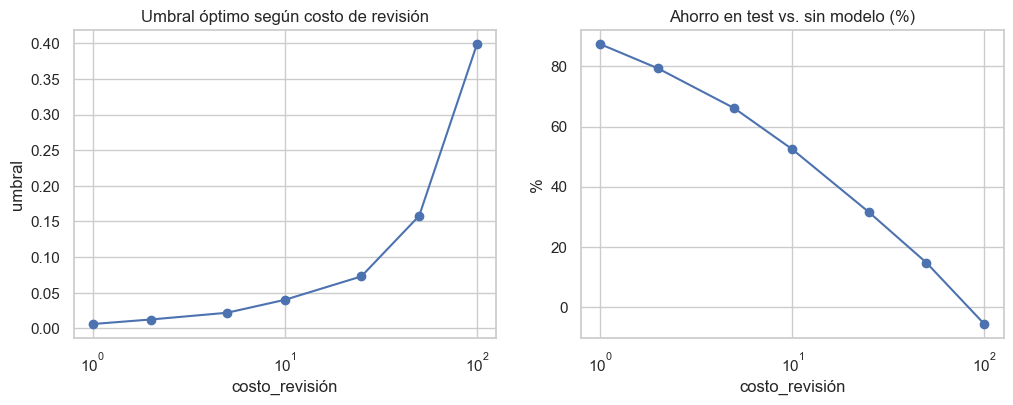

In [35]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sens["umbral"].replace(np.inf, np.nan).plot(marker="o", ax=ax[0], logx=True, title="Umbral óptimo según costo de revisión")
ax[0].set_ylabel("umbral")
sens["ahorro_vs_sin_modelo_%"].plot(marker="o", ax=ax[1], logx=True, title="Ahorro en test vs. sin modelo (%)")
ax[1].set_ylabel("%")
plt.savefig("../reports/figures/sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()

## 5. Interpretabilidad con SHAP
Se calculan los valores SHAP (contribuciones al log-odds de fraude) sobre una muestra de 10.000 transacciones de validación, usando el cálculo nativo de LightGBM (`pred_contrib`).

**Aclaración:** muchas variables están enmascaradas (`V1`-`V339`, `id_*`), por lo que se puede decir *cuánto* pesan pero no *qué representan*.

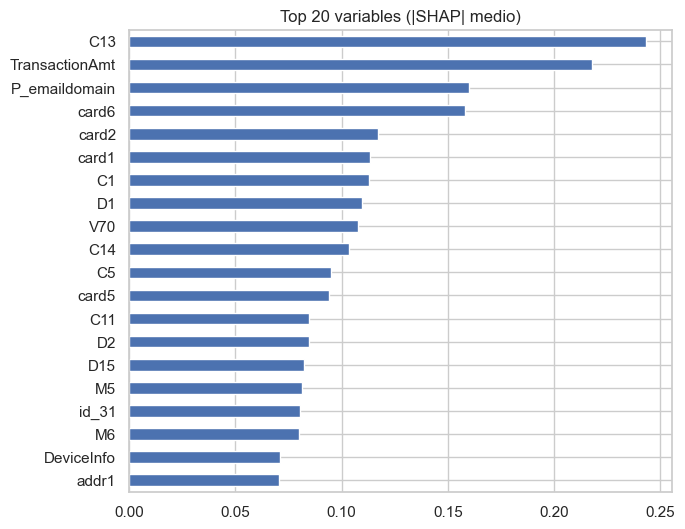

Variables enmascaradas (V*, id_*) en el top 20: 2 de 20
Peso de las enmascaradas sobre el |SHAP| total: 38.7%


In [36]:
sample = valid.sample(10000, random_state=0)
Xs = sample[features]

contrib = model.booster_.predict(Xs, pred_contrib=True)   # (n, n_features + 1)
sv, base = contrib[:, :-1], contrib[:, -1]

# versión numérica de X solo para graficar (las categóricas pasan a sus códigos)
Xplot = Xs.copy()
for c in Xplot.columns:
    if isinstance(Xplot[c].dtype, pd.CategoricalDtype):
        codes = Xplot[c].cat.codes
        Xplot[c] = codes.where(codes >= 0).astype("float32")

imp = pd.Series(np.abs(sv).mean(axis=0), index=features).sort_values(ascending=False)
imp.head(20).iloc[::-1].plot(kind="barh", figsize=(7, 6), title="Top 20 variables (|SHAP| medio)")
plt.show()

is_masked = imp.index.str.match(r"^(V\d+|id_\d+)$")
print(f"Variables enmascaradas (V*, id_*) en el top 20: {is_masked[:20].sum()} de 20")
print(f"Peso de las enmascaradas sobre el |SHAP| total: {100 * imp[is_masked].sum() / imp.sum():.1f}%")

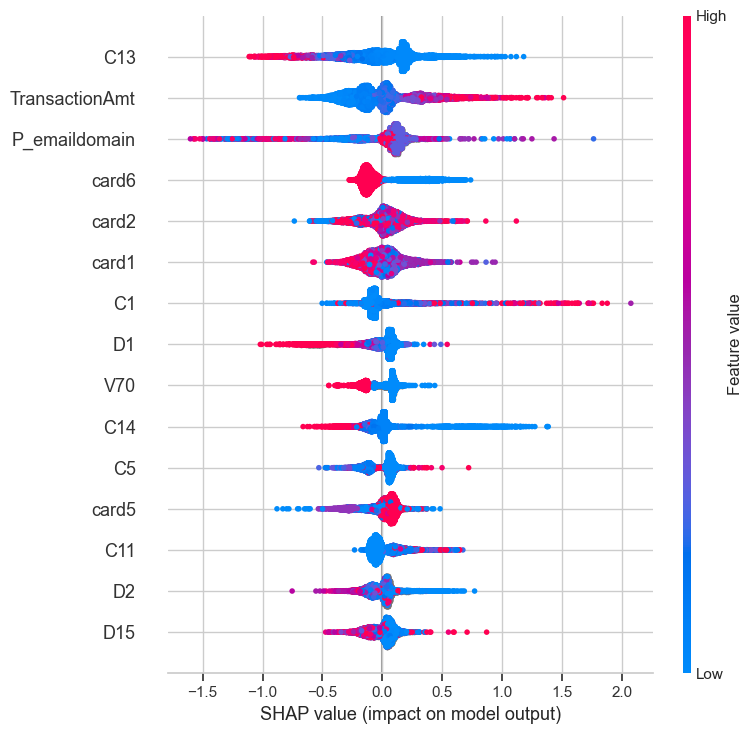

In [37]:
shap.summary_plot(sv, Xplot, max_display=15, show=False)
plt.savefig("../reports/figures/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

### Una predicción individual
Explicación de un fraude real con score alto de la muestra (valores en log-odds).

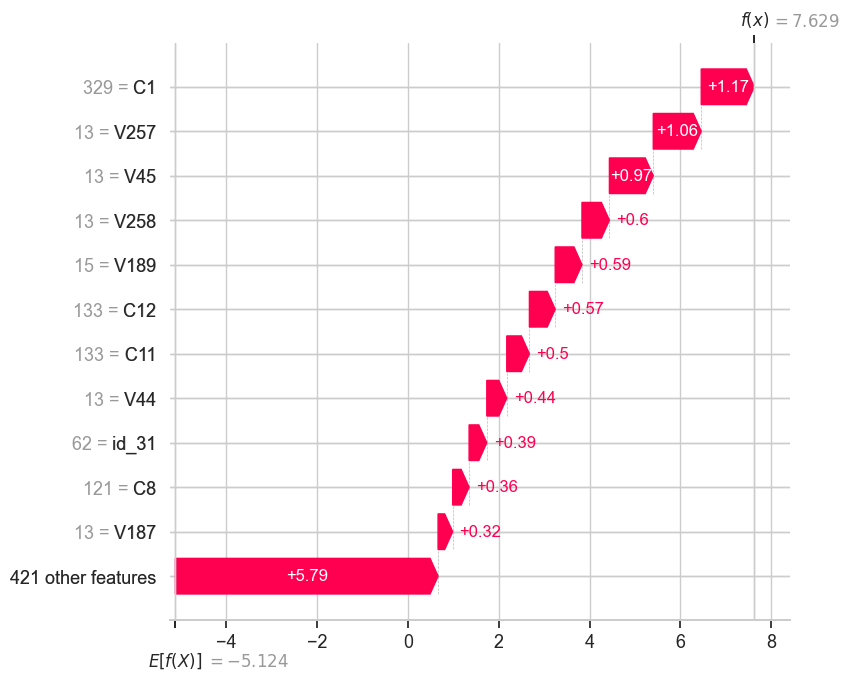

In [38]:
scores = model.predict_proba(Xs)[:, 1]
idx = int(np.argmax(np.where(sample["isFraud"].values == 1, scores, -1)))
exp = shap.Explanation(values=sv[idx], base_values=base[idx], data=Xplot.iloc[idx].values, feature_names=features)
shap.plots.waterfall(exp, max_display=12)

## 6. Conclusiones

**Resultado final en test:** AUC-PR 0,544 (15,7x la tasa base), AUC-ROC 0,906, recall con precisión ≥50% de 0,517 y con ≥80% de 0,353. Es inferior a validación (AUC-PR 0,617, promedio de 3 semillas del baseline). Causa probable: drift temporal (test es el tramo más lejano de train) y algo de optimismo en validación, que se usó para el early stopping y el umbral (hipótesis no verificada).

**Costo (revisión = 5 USD):** el umbral óptimo en validación (0,0217) genera alertas sobre ~15% de las transacciones. En test logra un ahorro de 66% frente a no tener modelo (168 mil vs 495 mil USD), con recall de 80% y precisión de 17,7%. El umbral 0,5 solo ahorra 21%: detecta 34% de los fraudes.

**Sensibilidad:** el valor del modelo depende del costo de revisión. Con 1 USD el ahorro es de 87%; con 50 USD, 15%; con 100 USD es negativo (-5,7%): el umbral de validación no transfirió bien a test y el modelo costó más que no hacer nada.

**Interpretabilidad (SHAP):** entre las variables más influyentes figuran `P_emaildomain` (tercera), `C13`, `TransactionAmt` y `card6`; `C1` también aparece en el top 20. Montos altos empujan hacia fraude; valores altos de `C13`, hacia no fraude. En `P_emaildomain` los colores se mezclan: su efecto depende del dominio y no sigue una dirección única. Las variables enmascaradas (`V*`, `id_*`) pesan poco por separado (2 del top 20) pero suman el 38,7% del |SHAP| total, lo que limita la interpretabilidad. SHAP describe qué usa el modelo, no qué causa el fraude.
- `card6`: las transacciones con tarjeta de crédito empujan hacia fraude y las de débito hacia no fraude, lo que coincide con las tasas observadas (6,7% frente a 2,4%).

**Limitaciones:** supuestos de costo propios (revisión fija y perfecta, pérdida = monto); sin contracargos ni fricción; un único corte temporal; modelo entrenado solo con train; resultado en test con una única semilla; hiperparámetros sin tuning.